# Parameter Optimization on Synthetic Data (Notebook 1 of 2)

**Goal:** use the synthetic Melcher25 dataset from `NGRIP_Parameter_Search_Melcher25.ipynb` —
where the true transition times are known exactly — to search for `KS_test` and `ruptures`
parameters that best recover those known transitions, scored with Ammonyte's own
`evaluate_detection` (precision/recall/F1), then hand the winning parameters to the companion
notebook (`NGRIP_Optimized_Parameters.ipynb`) to apply to real NGRIP.

**Cross-validation, not a single evaluation:** an earlier version of this notebook scored
every candidate parameter set against one fixed noisy realization and reported the best
score found — that's leakage (picking the best of N trials, then reporting that trial's
score on the same data used to pick it). This version follows the same seed-based K-fold CV
pattern already validated in `Noise_Sensitivity_Detection_CV.ipynb` / `cv_noise_sensitivity.py`:
parameters are selected using only a fold's training realizations, then scored once on that
fold's held-out realizations, which the selection step never saw.

**One scope difference from that reference pattern, worth being explicit about:** the
`noise_sensitivity` dataset's 20 "seeds" are fully independent Melcher25 simulations (fresh
stochastic dynamics *and* fresh noise each time). Here we only have one saved dynamics
trajectory (`best_config.json`, `base_seed=42`), and `climatecritters` isn't installed in this
environment, so the realizations built below vary **only the observation noise** on top of
that one fixed trajectory — ground truth (`true_transitions`) is identical across all of them
by construction. This still fully fixes the leakage problem (train/test realizations never
overlap), but it only tests robustness to noise-draw variability, not to the natural
variability of the underlying stochastic climate model.

**Methods covered:** `KS_test` (Bagniewski et al. 2021) and `ruptures` with three cheap
algorithm/cost combinations (`Binseg`+`l2`, `Window`+`l2`, `Pelt`+`rbf`). `x_c` is fixed to
`None` (auto-calculated per series) rather than searched, matching the reasoning already
settled on in `cv_noise_sensitivity.py`: it's an adaptive switch, not a value with a
principled fixed range.

**Structure**
- Section 1 — Load the synthetic ground truth
- Section 2 — Build noise realizations + CV harness (`calibrate` / `run_cv`, mirroring the
  validated smoke-test pattern)
- Section 3 — `KS_test`: K-fold CV, then final refit on all realizations
- Section 4 — `ruptures`: same, for 3 variants
- Section 5 — Best-parameters comparison plot
- Section 6 — Save summary table (CSV) + optimized parameters (JSON) for the NGRIP notebook

**Runtime note:** sized for a first laptop test (~15-20 min total). `N_SEEDS`, `N_FOLDS`, and
the `N_TRIALS_*` constants are the knobs to raise for a fuller search — this same
`calibrate`/`run_cv` code can move into a standalone script for CARC unchanged if that becomes
worthwhile.


In [1]:
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import qmc
from sklearn.model_selection import KFold

import ammonyte as amt
from ammonyte.utils.ks import KS_test
from ammonyte.utils.ruptures_transitions import ruptures_transition
from ammonyte.utils.metrics import evaluate_detection

DATA_DIR = "/Users/maryamniati/Documents/Syntheticdata"
TOLERANCE = 0.5  # kyr -- same +/-500yr matching window used in KS_test_Validation.ipynb / Ruptures_Validation.ipynb


---
## Section 1 — Load the Synthetic Ground Truth

Loads the outputs already saved by `NGRIP_Parameter_Search_Melcher25.ipynb`. `db_true` (the
noise-free trajectory) is what Section 2 will re-noise into multiple independent realizations;
`true_transitions` is the fixed ground truth all of them share.


In [2]:
example_df = pd.read_csv(f"{DATA_DIR}/example_synthetic_dataset.csv")
true_transitions = np.load(f"{DATA_DIR}/true_transition_times.npy")
best_config = json.load(open(f"{DATA_DIR}/best_config.json"))

time_arr = example_df['time'].values
db_true = example_df['db_true'].values
sigma_noise = best_config['sigma_noise']

# One originally-saved noisy realization, kept only for the Section 1 plot / Section 5 visual --
# not used for scoring anywhere below (that's the whole point of the CV rebuild).
synthetic_series = amt.Series(
    time=time_arr, value=example_df['db_noisy'].values,
    time_name='Time', time_unit='kyr', value_name='db', value_unit='',
    label='Synthetic (Melcher25, noisy, original realization)'
)

print(f"Series length: {len(time_arr)} points, {time_arr.min():.2f}-{time_arr.max():.2f} kyr")
print(f"Known ground-truth transitions: {len(true_transitions)}")
print(f"Source Melcher25 config: {best_config}")


Time axis values sorted in ascending order
Series length: 6001 points, 0.00-120.00 kyr
Known ground-truth transitions: 20
Source Melcher25 config: {'sigma': 0.37123522567804845, 'gamma': 1.4582277114299749, 'alpha': -0.44962706106886396, 'sigma_noise': 0.045750514542913644, 't_span': [0, 120], 'dt': 0.02, 'y0': [1.0, 0.0]}


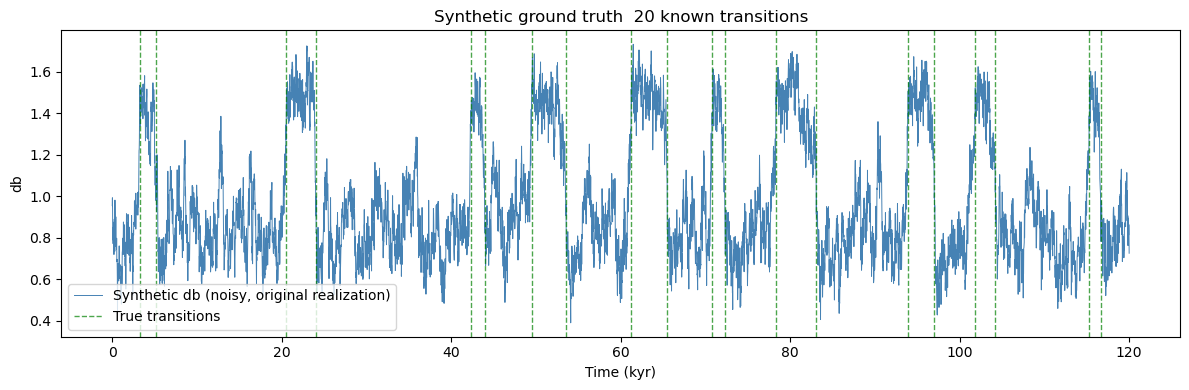

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(synthetic_series.time, synthetic_series.value, lw=0.7, color='steelblue', label='Synthetic db (noisy, original realization)')
for i, t in enumerate(true_transitions):
    ax.axvline(t, color='green', ls='--', lw=1.0, alpha=0.7, label='True transitions' if i == 0 else None)
ax.set_xlabel('Time (kyr)'); ax.set_ylabel('db')
ax.set_title(f'Synthetic ground truth  {len(true_transitions)} known transitions')
ax.legend(); plt.tight_layout(); plt.show()


---
## Section 2 — Noise Realizations + CV Harness

**Realizations:** `db_true + fresh white noise at the calibrated sigma_noise`, one independent
draw per seed. Ground truth doesn't depend on noise, so `gt_times` is the same array reused for
every seed -- that's expected, not a bug (see the intro note above).

**CV harness:** `calibrate()`/`run_cv()` below are a direct port of the pattern in
`Noise_Sensitivity_Detection_CV.ipynb` -- `calibrate()` only ever receives `train_idx` seeds
(picks the parameter combo with the best mean F1 across them), `run_cv()` wraps that in a
`KFold` loop and scores the calibrated params once on each fold's held-out `test_idx` seeds,
which `calibrate()` never touched.


In [4]:
N_SEEDS = 8
N_FOLDS = 3   # smoke-test-sized; raise once this runs cleanly

rng_noise = np.random.default_rng(123)
db_noisy_realizations = np.stack([
    db_true + rng_noise.normal(0, sigma_noise, size=len(db_true))
    for _ in range(N_SEEDS)
])
gt_times = [true_transitions] * N_SEEDS  # ground truth is fixed -- only observation noise varies

print(f"Built {N_SEEDS} independent noise realizations (sigma_noise={sigma_noise:.4f}), "
      f"{N_FOLDS}-fold CV -> ~{N_SEEDS - N_SEEDS // N_FOLDS} train / ~{N_SEEDS // N_FOLDS} test seeds per fold")


Built 8 independent noise realizations (sigma_noise=0.0458), 3-fold CV -> ~6 train / ~2 test seeds per fold


In [5]:
def _clean_times(times):
    times = np.asarray(times, dtype=float)
    return times[~np.isnan(times)]


def detect_kstest(time, value, w_min, w_max, n_w, d_c, n_c, s_c):
    series = amt.Series(time=time, value=value, label='cv', verbose=False)
    jumps, _, _ = KS_test(series, w_min=w_min, w_max=w_max, n_w=n_w, d_c=d_c, n_c=n_c, s_c=s_c, x_c=None)
    return _clean_times(jumps[:, 0])


def detect_ruptures(time, value, **params):
    series = amt.Series(time=time, value=value, label='cv', verbose=False)
    result = ruptures_transition(series, **params)
    return _clean_times(result.jump_times)


def _score_one(detect_fn, params, time, value, gt, tolerance=TOLERANCE):
    try:
        detected = detect_fn(time, value, **params)
    except Exception:
        return 0.0, 0.0, 0.0
    m = evaluate_detection(detected=detected, ground_truth=gt, tolerance=tolerance)
    return m.precision, m.recall, m.f1_score


def kfold_splits(n_seeds, n_folds=N_FOLDS, seed=0):
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=seed)
    return list(kf.split(np.arange(n_seeds)))


def calibrate(detect_fn, param_grid, time, db_noisy, gt_times, train_idx, tolerance=TOLERANCE, n_jobs=-1):
    '''Pick the parameter combo with the best mean F1 across train_idx seeds only.'''
    jobs = [(pi, s) for pi in range(len(param_grid)) for s in train_idx]
    results = Parallel(n_jobs=n_jobs)(
        delayed(_score_one)(detect_fn, param_grid[pi], time, db_noisy[s], gt_times[s], tolerance)
        for pi, s in jobs
    )
    f1_by_param = [[] for _ in param_grid]
    for (pi, _), (_, _, f1) in zip(jobs, results):
        f1_by_param[pi].append(f1)
    mean_f1 = [float(np.mean(v)) for v in f1_by_param]
    best_i = int(np.argmax(mean_f1))
    return param_grid[best_i], mean_f1[best_i]


def score_on_seeds(detect_fn, params, time, db_noisy, gt_times, seed_idx, tolerance=TOLERANCE, n_jobs=-1):
    '''Score one fixed parameter set on a set of seeds -- used only for held-out test_idx.'''
    results = Parallel(n_jobs=n_jobs)(
        delayed(_score_one)(detect_fn, params, time, db_noisy[s], gt_times[s], tolerance)
        for s in seed_idx
    )
    precisions, recalls, f1s = zip(*results)
    return float(np.mean(precisions)), float(np.mean(recalls)), float(np.mean(f1s))


def run_cv(method_name, detect_fn, param_grid, time, db_noisy, gt_times, n_folds=N_FOLDS):
    fold_results = []
    for fold_idx, (train_idx, test_idx) in enumerate(kfold_splits(db_noisy.shape[0], n_folds)):
        best_params, train_f1 = calibrate(detect_fn, param_grid, time, db_noisy, gt_times, train_idx)
        test_p, test_r, test_f1 = score_on_seeds(detect_fn, best_params, time, db_noisy, gt_times, test_idx)
        fold_results.append(dict(method=method_name, fold=fold_idx, train_f1=train_f1,
                                  test_precision=test_p, test_recall=test_r, test_f1=test_f1,
                                  best_params=best_params))
        print(f"  [{method_name}] fold {fold_idx}: train_f1={train_f1:.3f}  test_f1={test_f1:.3f}  params={best_params}")
    return fold_results


---
## Section 3 — `KS_test`: K-Fold CV + Final Refit

Latin hypercube search over the 6 free `KS_test` parameters (`x_c` fixed to `None`). Each
candidate is scored via `calibrate()`/`run_cv()` above -- honest, held-out `test_f1` per fold.
After CV, one more `calibrate()` call using **all** `N_SEEDS` (no held-out) produces the single
parameter set to actually hand to the NGRIP notebook; the CV fold average is the confidence
estimate attached to that choice.


In [6]:
N_TRIALS_KS = 20

ks_ranges = dict(
    w_min=(0.05, 0.6),
    w_max=(1.0, 4.0),
    n_w=(5, 20),
    d_c=(0.4, 0.95),
    n_c=(2, 6),
    s_c=(1.0, 3.0),
)
param_names_ks = list(ks_ranges.keys())
l_bounds = [ks_ranges[k][0] for k in param_names_ks]
u_bounds = [ks_ranges[k][1] for k in param_names_ks]

sampler = qmc.LatinHypercube(d=len(param_names_ks), seed=0)
scaled = qmc.scale(sampler.random(n=N_TRIALS_KS), l_bounds, u_bounds)

ks_grid = []
for row in scaled:
    p = {k: float(v) for k, v in zip(param_names_ks, row)}
    p['n_w'] = max(1, int(round(p['n_w'])))
    p['n_c'] = max(2, int(round(p['n_c'])))
    ks_grid.append(p)

t0 = time.time()
ks_fold_results = run_cv('KS_test', detect_kstest, ks_grid, time_arr, db_noisy_realizations, gt_times)
print(f"KS_test CV: {len(ks_grid)} candidates x {N_FOLDS} folds in {time.time() - t0:.1f}s")

ks_cv_df = pd.DataFrame(ks_fold_results)
ks_test_f1_mean = ks_cv_df['test_f1'].mean()
ks_test_f1_std = ks_cv_df['test_f1'].std()
print(f"\nKS_test CV estimate: test_f1 = {ks_test_f1_mean:.3f} +/- {ks_test_f1_std:.3f} across {N_FOLDS} folds")

t0 = time.time()
ks_final_params, ks_final_train_f1 = calibrate(detect_kstest, ks_grid, time_arr, db_noisy_realizations,
                                                gt_times, train_idx=np.arange(N_SEEDS))
print(f"Final refit on all {N_SEEDS} seeds ({time.time() - t0:.1f}s): {ks_final_params} "
      f"(mean F1 across all seeds = {ks_final_train_f1:.3f})")


  [KS_test] fold 0: train_f1=0.677  test_f1=0.680  params={'w_min': 0.5830769094342655, 'w_max': 3.342448366860718, 'n_w': 12, 'd_c': 0.8955270281836536, 'n_c': 6, 's_c': 1.7349540723732184}
  [KS_test] fold 1: train_f1=0.679  test_f1=0.675  params={'w_min': 0.5830769094342655, 'w_max': 3.342448366860718, 'n_w': 12, 'd_c': 0.8955270281836536, 'n_c': 6, 's_c': 1.7349540723732184}
  [KS_test] fold 2: train_f1=0.677  test_f1=0.679  params={'w_min': 0.5830769094342655, 'w_max': 3.342448366860718, 'n_w': 12, 'd_c': 0.8955270281836536, 'n_c': 6, 's_c': 1.7349540723732184}
KS_test CV: 20 candidates x 3 folds in 687.2s

KS_test CV estimate: test_f1 = 0.678 +/- 0.002 across 3 folds
Final refit on all 8 seeds (308.3s): {'w_min': 0.5830769094342655, 'w_max': 3.342448366860718, 'n_w': 12, 'd_c': 0.8955270281836536, 'n_c': 6, 's_c': 1.7349540723732184} (mean F1 across all seeds = 0.678)


---
## Section 4 — `ruptures`: K-Fold CV + Final Refit

Same `calibrate()`/`run_cv()` harness, applied to three cheap algorithm/cost combinations.
`Dynp`, `BottomUp`, and `KernelCPD` are skipped as too slow for this search size; `rbf` cost
is kept only for `Pelt` (fewer trials, since it's the slow one).


In [7]:
rng = np.random.default_rng(1)

N_TRIALS_BINSEG = 100
binseg_grid = [
    dict(algo='Binseg', cost='l2', pen=float(pen), min_size=int(ms), jump=1)
    for pen, ms in zip(rng.uniform(1, 50, N_TRIALS_BINSEG), rng.integers(2, 30, N_TRIALS_BINSEG))
]

N_TRIALS_WINDOW = 100
window_grid = [
    dict(algo='Window', cost='l2', pen=float(pen), min_size=int(ms), jump=1, width=int(w))
    for pen, ms, w in zip(rng.uniform(1, 50, N_TRIALS_WINDOW),
                           rng.integers(2, 30, N_TRIALS_WINDOW),
                           rng.integers(20, 300, N_TRIALS_WINDOW))
]


rupture_variants = {
    'ruptures_Binseg_l2': binseg_grid,
    'ruptures_Window_l2': window_grid,
}

ruptures_cv_results = {}
ruptures_final = {}

for name, grid in rupture_variants.items():
    t0 = time.time()
    fold_results = run_cv(name, detect_ruptures, grid, time_arr, db_noisy_realizations, gt_times)
    cv_df = pd.DataFrame(fold_results)
    ruptures_cv_results[name] = cv_df
    print(f"{name}: {len(grid)} candidates x {N_FOLDS} folds in {time.time() - t0:.1f}s -- "
          f"test_f1 = {cv_df['test_f1'].mean():.3f} +/- {cv_df['test_f1'].std():.3f}")

    final_params, final_train_f1 = calibrate(detect_ruptures, grid, time_arr, db_noisy_realizations,
                                              gt_times, train_idx=np.arange(N_SEEDS))
    ruptures_final[name] = (final_params, final_train_f1)
    print(f"  final refit on all seeds: {final_params} (mean F1 = {final_train_f1:.3f})")


  [ruptures_Binseg_l2] fold 0: train_f1=0.926  test_f1=0.947  params={'algo': 'Binseg', 'cost': 'l2', 'pen': 4.996078250812123, 'min_size': 7, 'jump': 1}
  [ruptures_Binseg_l2] fold 1: train_f1=0.937  test_f1=0.919  params={'algo': 'Binseg', 'cost': 'l2', 'pen': 2.94005095654594, 'min_size': 15, 'jump': 1}
  [ruptures_Binseg_l2] fold 2: train_f1=0.939  test_f1=0.921  params={'algo': 'Binseg', 'cost': 'l2', 'pen': 4.996078250812123, 'min_size': 7, 'jump': 1}
ruptures_Binseg_l2: 100 candidates x 3 folds in 68.0s -- test_f1 = 0.929 +/- 0.016
  final refit on all seeds: {'algo': 'Binseg', 'cost': 'l2', 'pen': 4.996078250812123, 'min_size': 7, 'jump': 1} (mean F1 = 0.934)
  [ruptures_Window_l2] fold 0: train_f1=0.299  test_f1=0.298  params={'algo': 'Window', 'cost': 'l2', 'pen': 2.2977428962946447, 'min_size': 14, 'jump': 1, 'width': 207}
  [ruptures_Window_l2] fold 1: train_f1=0.326  test_f1=0.255  params={'algo': 'Window', 'cost': 'l2', 'pen': 2.2977428962946447, 'min_size': 14, 'jump': 1

---
## Section 5 — Best-Parameters Comparison

Overlays the known true transitions with detections from the final refit `KS_test` config and
the best-CV-scoring `ruptures` variant, run on the original saved noisy realization purely for
a visual check -- the CV `test_f1` numbers above (not this one plot) are the quantitative
result.


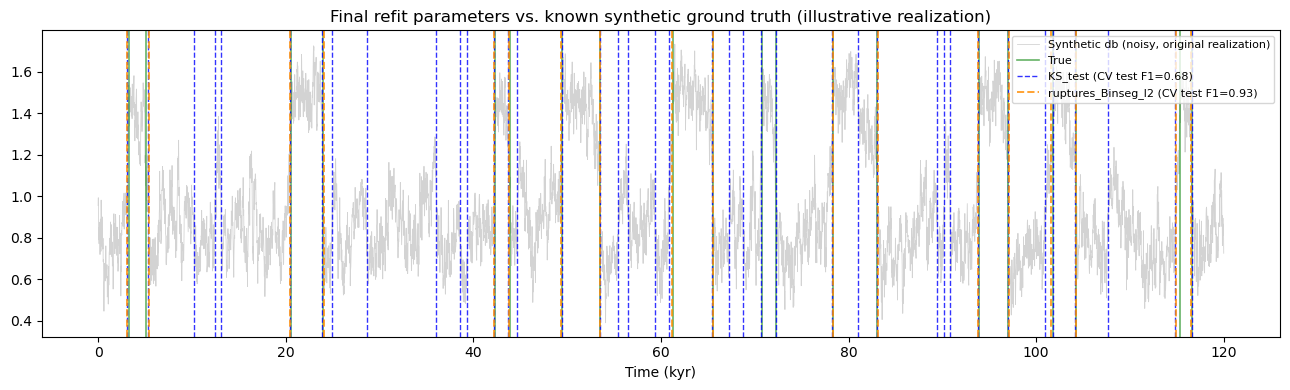

KS_test final params: {'w_min': 0.5830769094342655, 'w_max': 3.342448366860718, 'n_w': 12, 'd_c': 0.8955270281836536, 'n_c': 6, 's_c': 1.7349540723732184}
Best ruptures variant: ruptures_Binseg_l2  params: {'algo': 'Binseg', 'cost': 'l2', 'pen': 4.996078250812123, 'min_size': 7, 'jump': 1}


In [10]:
jumps, _, _ = KS_test(synthetic_series, **ks_final_params, x_c=None)
ks_detected = jumps[:, 0]
ks_detected = ks_detected[~np.isnan(ks_detected)]

best_ruptures_name = max(ruptures_cv_results, key=lambda k: ruptures_cv_results[k]['test_f1'].mean())
rupt_final_params, _ = ruptures_final[best_ruptures_name]
rupt_result = ruptures_transition(synthetic_series, **rupt_final_params)
rupt_detected = np.asarray(rupt_result.jump_times, dtype=float)
rupt_detected = rupt_detected[~np.isnan(rupt_detected)]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(synthetic_series.time, synthetic_series.value, lw=0.6, color='lightgray', label='Synthetic db (noisy, original realization)')
for i, t in enumerate(true_transitions):
    ax.axvline(t, color='green', ls='-', lw=1.2, alpha=0.6, label='True' if i == 0 else None)
for i, t in enumerate(ks_detected):
    ax.axvline(t, color='blue', ls='--', lw=1.0, alpha=0.8,
               label=f'KS_test (CV test F1={ks_test_f1_mean:.2f})' if i == 0 else None)
for i, t in enumerate(rupt_detected):
    ax.axvline(t, color='darkorange', ls='--', lw=1.4, alpha=0.8,
               label=f'{best_ruptures_name} (CV test F1={ruptures_cv_results[best_ruptures_name]["test_f1"].mean():.2f})' if i == 0 else None)
ax.set_xlabel('Time (kyr)')
ax.set_title('Final refit parameters vs. known synthetic ground truth (illustrative realization)')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"KS_test final params: {ks_final_params}")
print(f"Best ruptures variant: {best_ruptures_name}  params: {rupt_final_params}")


---
## Section 6 — Save Summary Table + Optimized Parameters

Same two outputs as before, now sourced from the CV results: the deployed parameter set comes
from the final all-seeds refit, and the reported score is the honest CV `test_f1`
(mean +/- std across folds) rather than a single leaked number.


In [9]:
summary_rows = []

summary_rows.append(dict(
    method='KS_test',
    **ks_final_params,
    f1_score=ks_test_f1_mean, f1_std=ks_test_f1_std,
    n_folds=N_FOLDS, n_seeds=N_SEEDS, n_candidates=len(ks_grid),
))

for name, grid in rupture_variants.items():
    final_params, _ = ruptures_final[name]
    cv_df = ruptures_cv_results[name]
    summary_rows.append(dict(
        method=name,
        **final_params,
        f1_score=cv_df['test_f1'].mean(), f1_std=cv_df['test_f1'].std(),
        n_folds=N_FOLDS, n_seeds=N_SEEDS, n_candidates=len(grid),
    ))

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(f"{DATA_DIR}/optimized_parameters_summary.csv", index=False)

methods_json = {}
for row in summary_rows:
    row = dict(row)
    method_name = row.pop('method')
    n_folds = row.pop('n_folds')
    n_seeds = row.pop('n_seeds')
    n_candidates = row.pop('n_candidates')
    score = dict(f1_score=row.pop('f1_score'), f1_std=row.pop('f1_std'))
    methods_json[method_name] = dict(params=row, score=score,
                                      n_folds=n_folds, n_seeds=n_seeds, n_candidates=n_candidates)

output_json = dict(
    generated=pd.Timestamp.now().strftime('%Y-%m-%d'),
    synthetic_source=(f"best_config.json (Melcher25, sigma={best_config['sigma']:.3f}, "
                       f"gamma={best_config['gamma']:.3f}, alpha={best_config['alpha']:.3f}, "
                       f"sigma_noise={best_config['sigma_noise']:.3f})"),
    tolerance_kyr=TOLERANCE,
    cv_note=("f1_score/f1_std are K-fold CV test-set estimates (parameters selected on train "
             "seeds only, scored on held-out seeds never used for selection); realizations vary "
             "only observation noise on one fixed dynamics trajectory, not full Melcher25 reruns."),
    methods=methods_json,
)
with open(f"{DATA_DIR}/optimized_parameters.json", 'w') as f:
    json.dump(output_json, f, indent=2)

ks_cv_df.drop(columns=[]).to_csv(f"{DATA_DIR}/cv_results_KS_test.csv", index=False)
for name, cv_df in ruptures_cv_results.items():
    cv_df.to_csv(f"{DATA_DIR}/cv_results_{name}.csv", index=False)

print("Saved:")
print(f"  {DATA_DIR}/optimized_parameters.json")
print(f"  {DATA_DIR}/optimized_parameters_summary.csv")
print(f"  {DATA_DIR}/cv_results_KS_test.csv")
for name in ruptures_cv_results:
    print(f"  {DATA_DIR}/cv_results_{name}.csv")

summary_df


Saved:
  /Users/maryamniati/Documents/Syntheticdata/optimized_parameters.json
  /Users/maryamniati/Documents/Syntheticdata/optimized_parameters_summary.csv
  /Users/maryamniati/Documents/Syntheticdata/cv_results_KS_test.csv
  /Users/maryamniati/Documents/Syntheticdata/cv_results_ruptures_Binseg_l2.csv
  /Users/maryamniati/Documents/Syntheticdata/cv_results_ruptures_Window_l2.csv


,method,w_min,w_max,n_w,d_c,n_c,s_c,f1_score,f1_std,n_folds,n_seeds,n_candidates,algo,cost,pen,min_size,jump,width
0,KS_test,0.583077,3.342448,12.0,0.895527,6.0,1.734954,0.677855,0.002351,3,8,20,NaN,NaN,NaN,NaN,NaN,NaN
1,ruptures_Binseg_l2,NaN,NaN,NaN,NaN,NaN,NaN,0.929156,0.015804,3,8,100,Binseg,l2,4.996078,7.0,1.0,NaN
2,ruptures_Window_l2,NaN,NaN,NaN,NaN,NaN,NaN,0.283353,0.024957,3,8,100,Window,l2,2.297743,14.0,1.0,207.0
